<a href="https://colab.research.google.com/github/leadministrador/aprendizaje-automatico-i/blob/main/Parcial2_Grupo4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leadministrador/aprendizaje-automatico-i/blob/main/Parcial2_Grupo4.ipynb)

# Segundo parcial · Aprendizaje Automático I · Grupo 4
Estimar el nivel del **PBI** (Y) en relación a la **pobreza** y la **deserción escolar** (X) en las provincias argentinas.
`Tabla_GDP_1parcial.xlsx` desde GitHub

In [1]:
# Trae la base desde GitHub a Colab
# !wget = comando para descargar un archivo de internet; -q = sin mensajes; -nc = no lo baja de nuevo si ya está
!wget -q -nc https://raw.githubusercontent.com/leadministrador/aprendizaje-automatico-i/main/Tabla_GDP_1parcial.xlsx

## Paso 1 · Librerías

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from scipy.cluster import hierarchy

## Paso 2 · Cargar la base

In [3]:
tabla = pd.read_excel('Tabla_GDP_1parcial.xlsx')
t2 = pd.DataFrame(tabla)
t2

,province,gdp,illiteracy,poverty,deficient_infra,school_dropout,no_healthcare,birth_mortal,pop,movie_theatres_per_cap,doctors_per_cap
0,Buenos Aires,2.926899e+08,1.383240,8.167798,5.511856,0.766168,48.7947,4.4,15625084.0,0.000006,0.004836
1,Catamarca,6.150949e+06,2.344140,9.234095,10.464484,0.951963,45.0456,1.5,367828.0,0.000005,0.004502
2,Córdoba,6.936374e+07,2.714140,5.382380,10.436086,1.035056,45.7640,4.8,3308876.0,0.000011,0.010175
3,Corrientes,7.968013e+06,NaN,12.747191,17.438858,3.864265,62.1103,5.9,992595.0,0.000004,0.004495
4,Chaco,9.832643e+06,7.517580,15.862619,31.479527,2.577462,65.5104,7.5,NaN,0.000003,0.003605
5,Chubut,1.774785e+07,1.548060,NaN,8.044618,0.586309,39.5473,3.0,509108.0,0.000016,0.004498
6,Entre Ríos,2.074341e+07,3.185580,7.288751,18.794568,NaN,NaN,3.1,1235994.0,0.000006,0.004679
7,Formosa,3.807057e+06,4.610640,17.035583,28.004985,2.268974,65.8126,16.2,530162.0,0.000004,0.003440
8,Jujuy,NaN,2.151390,13.367965,NaN,0.721295,54.1615,3.7,673307.0,0.000003,0.003958
9,La Pampa,6.990262e+06,1.539300,3.398774,16.505714,0.204093,45.4764,NaN,318951.0,0.000019,0.005415


## Paso 3 · Tipos y duplicados

In [4]:
t2.dtypes

,0
province,object
gdp,float64
illiteracy,float64
poverty,float64
deficient_infra,float64
school_dropout,float64
no_healthcare,float64
birth_mortal,float64
pop,float64
movie_theatres_per_cap,float64


In [5]:
print('Duplicados:', t2.duplicated().sum())
t2[t2.duplicated(keep=False)]

Duplicados: 2


,province,gdp,illiteracy,poverty,deficient_infra,school_dropout,no_healthcare,birth_mortal,pop,movie_theatres_per_cap,doctors_per_cap
7,Formosa,3.807057e+06,4.61064,17.035583,28.004985,2.268974,65.8126,16.2,530162.0,0.000004,0.00344
14,Formosa,3.807057e+06,4.61064,17.035583,28.004985,2.268974,65.8126,16.2,530162.0,0.000004,0.00344
23,Formosa,3.807057e+06,4.61064,17.035583,28.004985,2.268974,65.8126,16.2,530162.0,0.000004,0.00344


In [6]:
t2.drop_duplicates(inplace=True)
print('Filas:', len(t2))

Filas: 22


## Paso 4 · Valores nulos
El PBI es la variable a estimar: las filas sin PBI se eliminan. Pobreza y deserción se completan con la mediana.

In [7]:
t2.isna().sum().sort_values()

,0
province,0
movie_theatres_per_cap,0
birth_mortal,1
poverty,1
pop,1
doctors_per_cap,1
deficient_infra,1
illiteracy,2
no_healthcare,2
school_dropout,2


In [8]:
t2 = t2.dropna(subset=['gdp'])
print('Filas con PBI:', len(t2))

Filas con PBI: 20


In [9]:
imp = SimpleImputer(missing_values=np.nan, strategy='median')
t2[['poverty','school_dropout']] = imp.fit_transform(t2[['poverty','school_dropout']])
print('Medianas usadas:', imp.statistics_)
t2[['gdp','poverty','school_dropout']].isna().sum()

Medianas usadas: [9.23409512 1.74110119]


/tmp/ipykernel_496/3704505033.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  t2[['poverty','school_dropout']] = imp.fit_transform(t2[['poverty','school_dropout']])


,0
gdp,0
poverty,0
school_dropout,0


## Paso 5 · Correlación

                     gdp   poverty  school_dropout
gdp             1.000000 -0.247589       -0.235586
poverty        -0.247589  1.000000        0.395012
school_dropout -0.235586  0.395012        1.000000


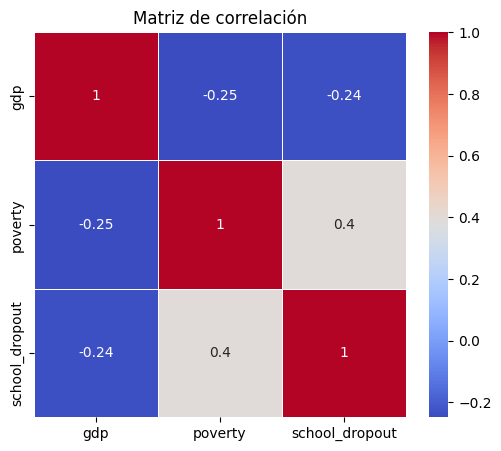

In [10]:
corr = t2[['gdp','poverty','school_dropout']].corr()
print(corr)
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Matriz de correlación')
plt.show()

# MODELO 1 · Regresión lineal múltiple
X = pobreza y deserción · Y = PBI

## Paso 6 · Definir X e Y y dividir

In [11]:
t2.index = t2['province']
x = pd.DataFrame(t2, columns=['poverty','school_dropout'])
y = pd.DataFrame(t2, columns=['gdp'])
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=41)
print('x_train shape:', x_train.shape)
print('x_test shape:', x_test.shape)
y_test

x_train shape: (14, 2)
x_test shape: (6, 2)


,gdp
province,
Mendoza,3.343137e+07
Misiones,9.646826e+06
San Juan,8.262309e+06
Entre Ríos,2.074341e+07
Chaco,9.832643e+06
San Luis,1.178085e+07


## Paso 7 · Entrenar y obtener la ecuación

In [12]:
model = LinearRegression()
model.fit(x_train, y_train)
print('Coeficientes (b1, b2):', model.coef_)
print('Término independiente (b0):', model.intercept_)

Coeficientes (b1, b2): [[-4766503.91086638 -5263770.97635939]]
Término independiente (b0): [96213133.87162673]


## Paso 8 · Predecir y comparar

In [13]:
pred = model.predict(x_test)
pred = np.array(pred, dtype=float)
y_test2 = np.array(y_test, dtype=float)
pd.DataFrame({'Valor_Real': y_test2.flatten(), 'Valor_Pred': pred.flatten()}, index=y_test.index)

,Valor_Real,Valor_Pred
province,,
Mendoza,3.343137e+07,5.991363e+07
Misiones,9.646826e+06,1.525235e+07
San Juan,8.262309e+06,3.571045e+07
Entre Ríos,2.074341e+07,5.230652e+07
Chaco,9.832643e+06,7.036727e+06
San Luis,1.178085e+07,5.425545e+07


## Paso 9 · Métricas

In [14]:
yt = y_test2.flatten()
pp = pred.flatten()
mae = mean_absolute_error(yt, pp)
mse = mean_squared_error(yt, pp)
rmse = mse ** (1/2.0)
print("The mean absolute error (MAE) on test set: {:.2f}".format(mae))
print("The mean squared error (MSE) on test set: {:.2f}".format(mse))
print("The root mean squared error (RMSE) on test set: {:.2f}".format(rmse))
print('Variance score (R2): %.3f' % r2_score(yt, pp))

The mean absolute error (MAE) on test set: 22728258.11
The mean squared error (MSE) on test set: 715711802818055.88
The root mean squared error (RMSE) on test set: 26752790.56
Variance score (R2): -7.918


## Paso 10 · Gráfico 3D del plano de regresión

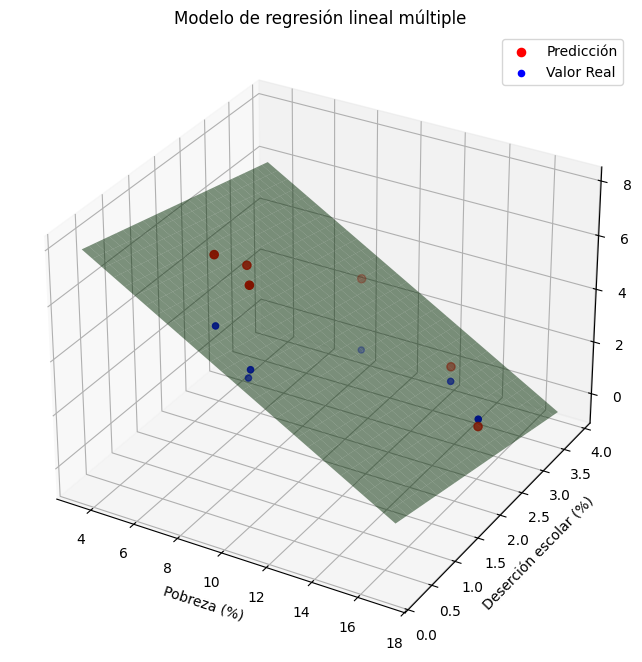

In [15]:
nx = np.array(x_test[['poverty']], dtype=float)
ny = np.array(x_test[['school_dropout']], dtype=float)
nz = pred

fig = plt.figure()
fig.set_size_inches(8, 9)
ax = fig.add_subplot(111, projection='3d')
ax.scatter(nx, ny, nz, c='red', s=35, label='Predicción')
ax.scatter(nx, ny, y_test2, c='blue', s=20, label='Valor Real')

nx_range = np.linspace(x['poverty'].min(), x['poverty'].max(), 30)
ny_range = np.linspace(x['school_dropout'].min(), x['school_dropout'].max(), 30)
NX, NY = np.meshgrid(nx_range, ny_range)
NZ = model.predict(pd.DataFrame({'poverty': NX.ravel(), 'school_dropout': NY.ravel()}))
NZ = NZ.reshape(NX.shape)
ax.plot_surface(NX, NY, NZ, alpha=0.5, color='green')

ax.set_xlabel('Pobreza (%)')
ax.set_ylabel('Deserción escolar (%)')
ax.set_zlabel('PBI')
ax.set_title('Modelo de regresión lineal múltiple')
plt.legend()
plt.show()

# MODELO 2 · Clustering jerárquico
X = pobreza · Y = PBI (estandarizadas)

## Paso 11 · Seleccionar y estandarizar las variables

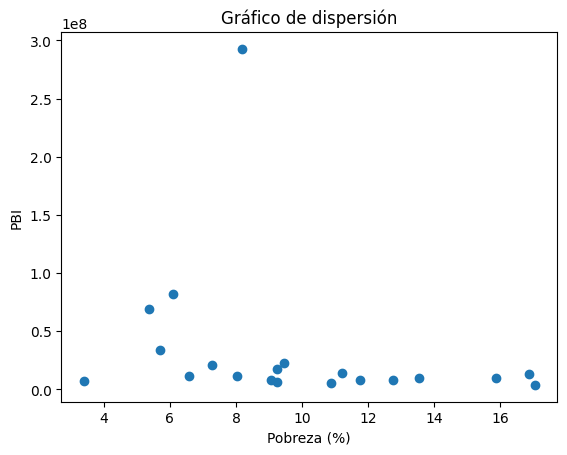

,poverty,gdp
province,,
Buenos Aires,-0.453447,4.130449
Catamarca,-0.170227,-0.423102
Córdoba,-1.193281,0.581448
Corrientes,0.762886,-0.394226
Chaco,1.590376,-0.364594
Chubut,-0.170227,-0.238809
Entre Ríos,-0.686930,-0.191205
Formosa,1.901927,-0.460350
La Pampa,-1.720147,-0.409764


In [16]:
xc = np.array(t2['poverty'], dtype=float)
yc = np.array(t2['gdp'], dtype=float)

plt.scatter(xc, yc)
plt.xlabel('Pobreza (%)')
plt.ylabel('PBI')
plt.title('Gráfico de dispersión')
plt.show()

td = pd.DataFrame({'poverty': xc, 'gdp': yc})
scaler = StandardScaler()
td[['poverty','gdp']] = scaler.fit_transform(td[['poverty','gdp']])
td.index = t2['province']
td

## Paso 12 · Enlace jerárquico

In [17]:
clus = hierarchy.linkage(td, 'single')
clus

array([[ 1.        , 14.        ,  0.05913069,  2.        ],
       [ 5.        , 12.        ,  0.09670507,  2.        ],
       [20.        , 21.        ,  0.15840843,  4.        ],
       [ 7.        , 13.        ,  0.15922061,  2.        ],
       [ 9.        , 19.        ,  0.15926625,  2.        ],
       [18.        , 24.        ,  0.168784  ,  3.        ],
       [ 3.        , 11.        ,  0.20957072,  2.        ],
       [ 6.        , 15.        ,  0.23315418,  2.        ],
       [16.        , 27.        ,  0.24297471,  3.        ],
       [25.        , 26.        ,  0.26255814,  5.        ],
       [ 2.        , 17.        ,  0.26865611,  2.        ],
       [ 4.        , 23.        ,  0.27376863,  3.        ],
       [22.        , 28.        ,  0.27783082,  7.        ],
       [10.        , 32.        ,  0.41910103,  8.        ],
       [29.        , 33.        ,  0.43597217, 13.        ],
       [30.        , 34.        ,  0.57694322, 15.        ],
       [31.        , 35.

## Paso 13 · Dendrograma con corte

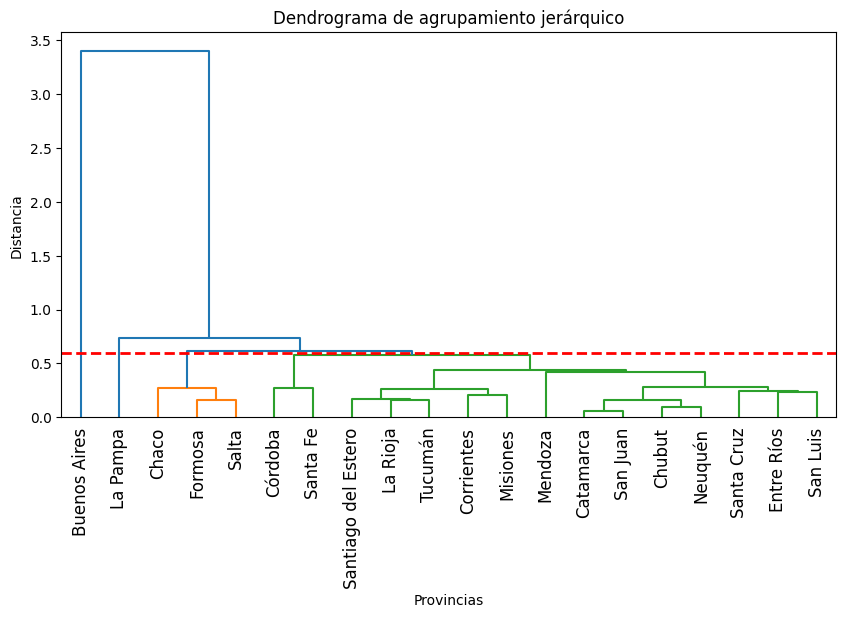

In [18]:
plt.figure(figsize=(10, 5))
dendrogram = hierarchy.dendrogram(clus, labels=td.index, color_threshold=0.6, leaf_rotation=90)
plt.title('Dendrograma de agrupamiento jerárquico')
plt.xlabel('Provincias')
plt.ylabel('Distancia')
plt.axhline(y=0.6, color='red', linestyle='--', linewidth=2)
plt.show()

# MODELO 3 · K-means
X = pobreza · Y = PBI (mismas variables estandarizadas)

## Paso 14 · Método del codo

[40.00000000000001, 24.079010080415763, 7.60436462482731, 3.8111206515507923, 2.3024552812226498, 1.7375623855472466, 0.8907965498356895, 0.5048421818779686, 0.4486732095492117, 0.24533643122247142]


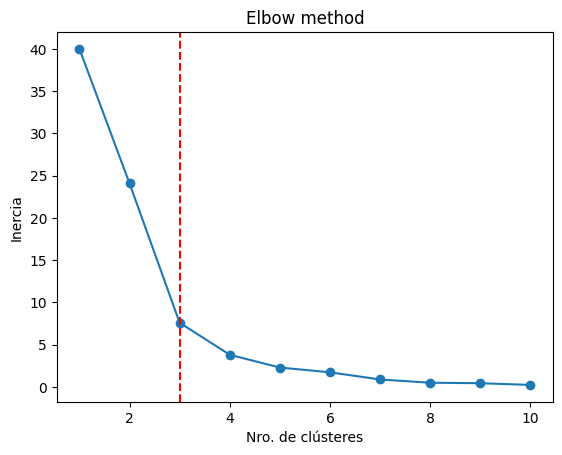

In [19]:
data = list(zip(td['poverty'], td['gdp']))

inertias = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(data)
    inertias.append(kmeans.inertia_)
print(inertias)

plt.plot(range(1, 11), inertias, marker='o')
plt.title('Elbow method')
plt.xlabel('Nro. de clústeres')
plt.ylabel('Inercia')
plt.axvline(x=3, color='red', linestyle='--')
plt.show()

## Paso 15 · Silueta para k = 2, 3 y 4

In [20]:
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(data)
    print('k =', k, ' Silhouette Score:', silhouette_score(data, labels))

k = 2  Silhouette Score: 0.41239258668833223
k = 3  Silhouette Score: 0.4845090501283926
k = 4  Silhouette Score: 0.44796265091991394


## Paso 16 · K-means con k = 3

In [21]:
kmeans3 = KMeans(n_clusters=3, random_state=42)
kmeans3.fit(data)
print('Centroides (estandarizados):', kmeans3.cluster_centers_)
print('Centroides (pobreza %, PBI):', scaler.inverse_transform(kmeans3.cluster_centers_))
print('Inercia:', kmeans3.inertia_)

datakm = pd.DataFrame({'poverty': xc, 'gdp': yc}, index=t2['province'])
datakm['cluster'] = kmeans3.labels_
datakm.sort_values('cluster')

Centroides (estandarizados): [[ 1.02572571 -0.37677714]
 [-0.70475992 -0.10147559]
 [-0.45344652  4.13044857]]
Centroides (pobreza %, PBI): [[1.37367590e+01 9.06599339e+06]
 [7.22162341e+00 2.63897523e+07]
 [8.16779764e+00 2.92689868e+08]]
Inercia: 7.60436462482731


,poverty,gdp,cluster
province,,,
Corrientes,12.747191,7.968013e+06,0
Chaco,15.862619,9.832643e+06,0
Formosa,17.035583,3.807057e+06,0
La Rioja,10.875152,5.590516e+06,0
Misiones,13.529788,9.646826e+06,0
Salta,16.870500,1.343883e+07,0
Santiago del Estero,11.759000,8.387859e+06,0
Tucumán,11.214239,1.385620e+07,0
Mendoza,5.692798,3.343137e+07,1


## Paso 17 · Gráfico de los grupos

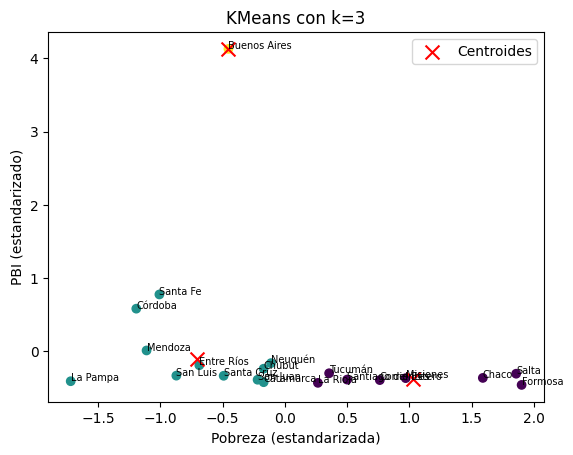

In [22]:
plt.scatter(td['poverty'], td['gdp'], c=kmeans3.labels_, cmap='viridis')
for i, label in enumerate(td.index):
    plt.text(td['poverty'].iloc[i], td['gdp'].iloc[i], label, fontsize=7)

centroids = kmeans3.cluster_centers_
plt.scatter(centroids[:,0], centroids[:,1], c='red', marker='x', s=100, label='Centroides')
plt.title('KMeans con k=3')
plt.xlabel('Pobreza (estandarizada)')
plt.ylabel('PBI (estandarizado)')
plt.legend()
plt.show()